# Week 9 - Multivariate Analysis, part 2

# 1. Lesson - no lesson this week

# 2. Weekly graph question

The graph below plots the first two principal component scores in a scatter plot.  What can be said about the three outliers in the upper left corner of the graph?  Is their first principal component score high or low?  What about their second principal component score?  What does that mean about their values in series_1, series_2, and series_3?  It seems to me that you can say something about series_3 (what can you say?) but you may have a harder time saying something about series_1 and series_2, and an almost impossible time saying anything about the relative values of series_1 and series_2.  Why is that?  How are series_1 and series_2 related, according to how they were created?  If you like, try drawing a pairplot for all three series and see what you get.

Overall, what are the advantages and disadvantages of the graph below?  Does it show anything interesting?

In [39]:
%pip install numpy pandas matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


[0.79916477 0.18990532 0.01092991]
[[ 0.26541493  0.30096233  0.91595665]
 [ 0.60337553  0.6891417  -0.40127506]
 [ 0.75199261 -0.65917023 -0.00131519]]


Text(0, 0.5, 'Second Principal Component Score')

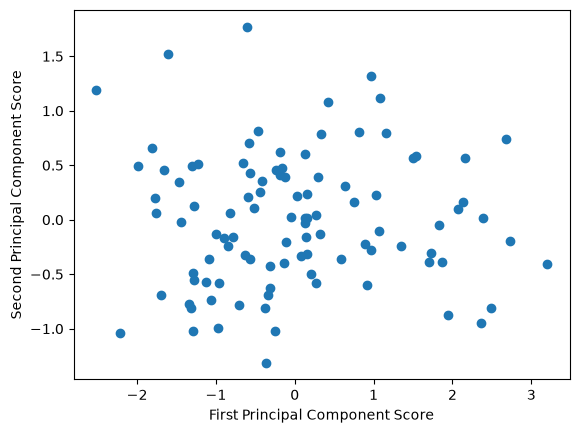

In [40]:
import numpy as np
import pandas as pd
from sklearn import decomposition
import matplotlib.pyplot as plt

np.random.seed(0)
num_points = 100
series_1 = np.random.normal(loc = 2, scale = 0.5, size = num_points)
series_2 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.1, size = num_points))
series_3 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.5, size = num_points))
df = pd.DataFrame({'ser1': series_1, 'ser2': series_2, 'ser3': series_3})
df = df - df.mean() # set mean to zero, so we don't have to subtract mean from the principal component scores

pca3 = decomposition.PCA(n_components = 3)
pca3.fit(df)
print(pca3.explained_variance_ratio_)
print(pca3.components_)

first_principal_component_score = df.dot(pca3.components_[0])
second_principal_component_score = df.dot(pca3.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score")

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:
Draw heatmaps.

Draw bubble plots.

Perform Principal Component Analysis to find out the directions in which the data varies.  Can you represent the data using only its projection onto its first principal component, using the methods described in Week 8?  How much of the variance would this capture?

Try performing linear regression analysis using different sets of features.  Which features seem most likely to be useful to predict other features?

Conclusions:
Explain what conclusions you would draw from this analysis: are the data what you expect? Are the data likely to be usable? If the data are not useable, find some new data!

Do you see any outliers? (Data points that are far from the rest of the data).

Does the Principal Component Analysis suggest a way to represent the data using fewer dimensions than usual - using its first one or two principal component scores, perhaps?

Try using your correlation information from previous weeks to help choose features for linear regression.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('Life Expectancy Data.csv')

# Clean column names
df.columns = df.columns.str.strip()

print(df.head())
print(df.shape)
print(df.info())

       Country  Year      Status  Life expectancy  Adult Mortality  \
0  Afghanistan  2015  Developing             65.0            263.0   
1  Afghanistan  2014  Developing             59.9            271.0   
2  Afghanistan  2013  Developing             59.9            268.0   
3  Afghanistan  2012  Developing             59.5            272.0   
4  Afghanistan  2011  Developing             59.2            275.0   

   infant deaths  Alcohol  percentage expenditure  Hepatitis B  Measles  ...  \
0             62     0.01               71.279624         65.0     1154  ...   
1             64     0.01               73.523582         62.0      492  ...   
2             66     0.01               73.219243         64.0      430  ...   
3             69     0.01               78.184215         67.0     2787  ...   
4             71     0.01                7.097109         68.0     3013  ...   

   Polio  Total expenditure  Diphtheria  HIV/AIDS         GDP  Population  \
0    6.0             

I loaded the Life Expectancy dataset and examined its structure. The dataset contains information about different countries, including their health conditions, education levels, and economic indicators.

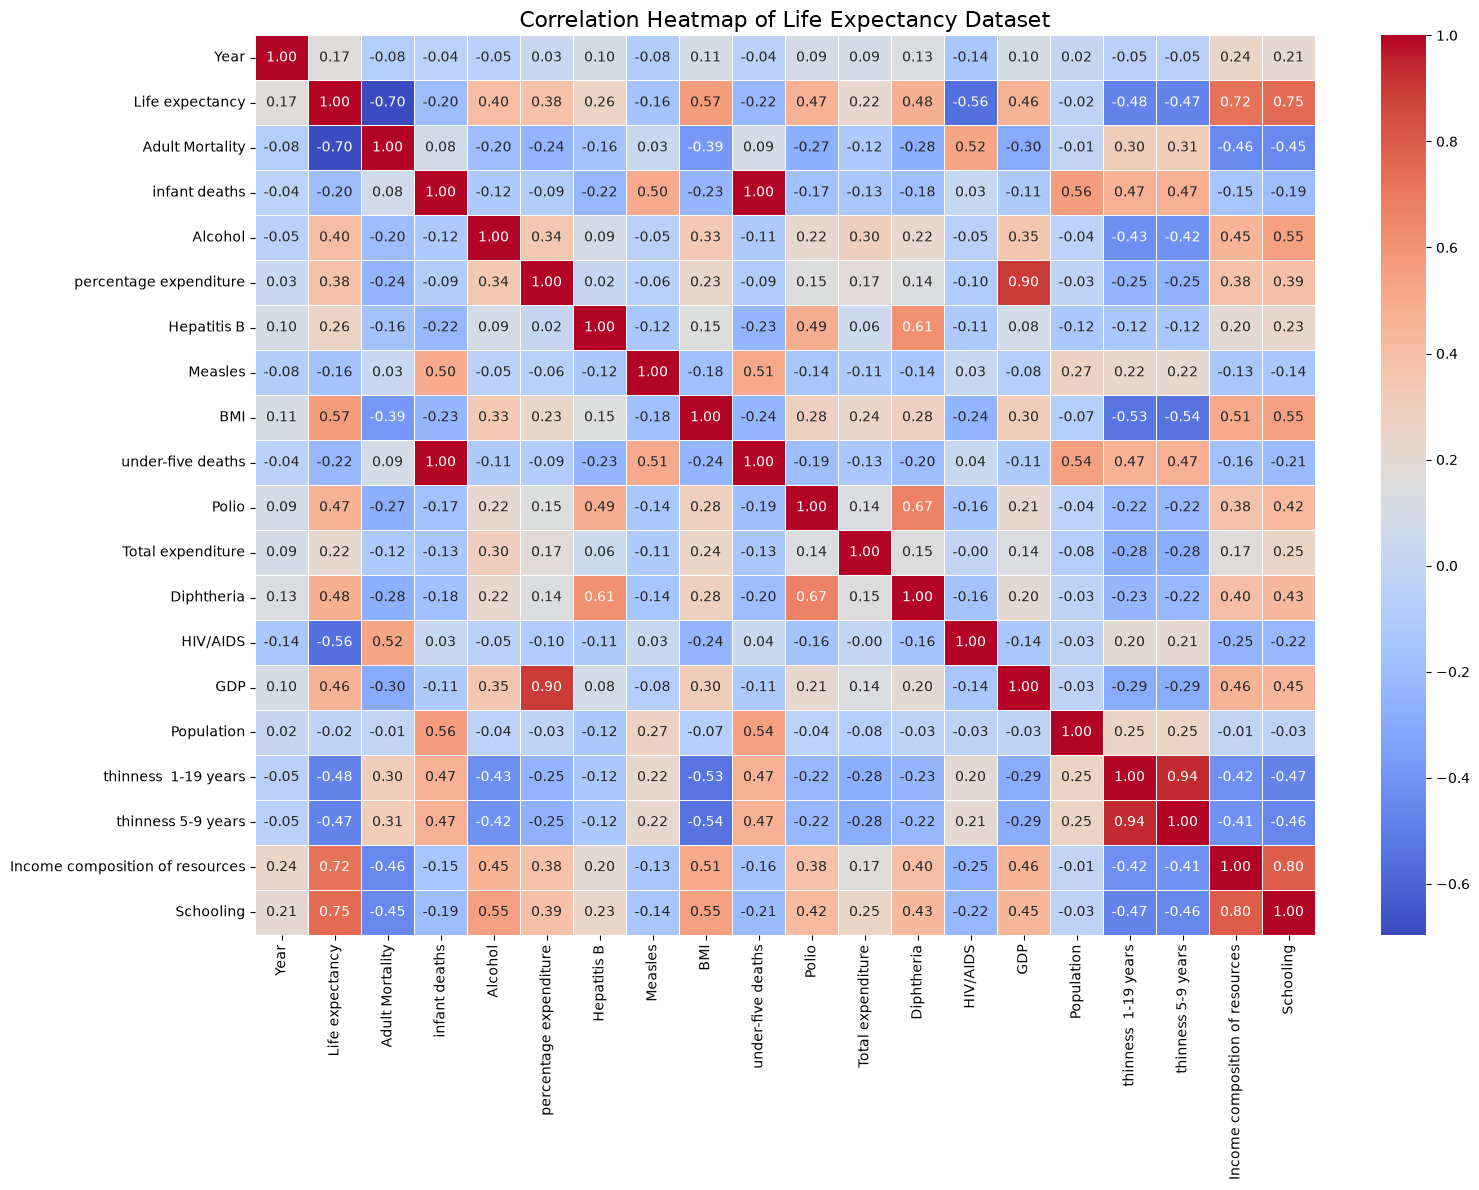

In [42]:
# Calculate correlation between numerical variables
correlation = df.select_dtypes(include=np.number).corr()

# Create heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Life Expectancy Dataset',
          fontsize=16)

plt.tight_layout()
plt.show()

The correlation heatmap helps identify relationships between different variables in the dataset. Schooling and income composition of resources show positive relationships with life expectancy. Adult mortality and HIV/AIDS show negative relationships.

This suggests that education, economic conditions, and health indicators are associated with differences in life expectancy.

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Life Expectancy Data.csv')

# Clean column names
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(r'\s+', ' ', regex=True)

# Check column names
print(df.columns.tolist())

['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


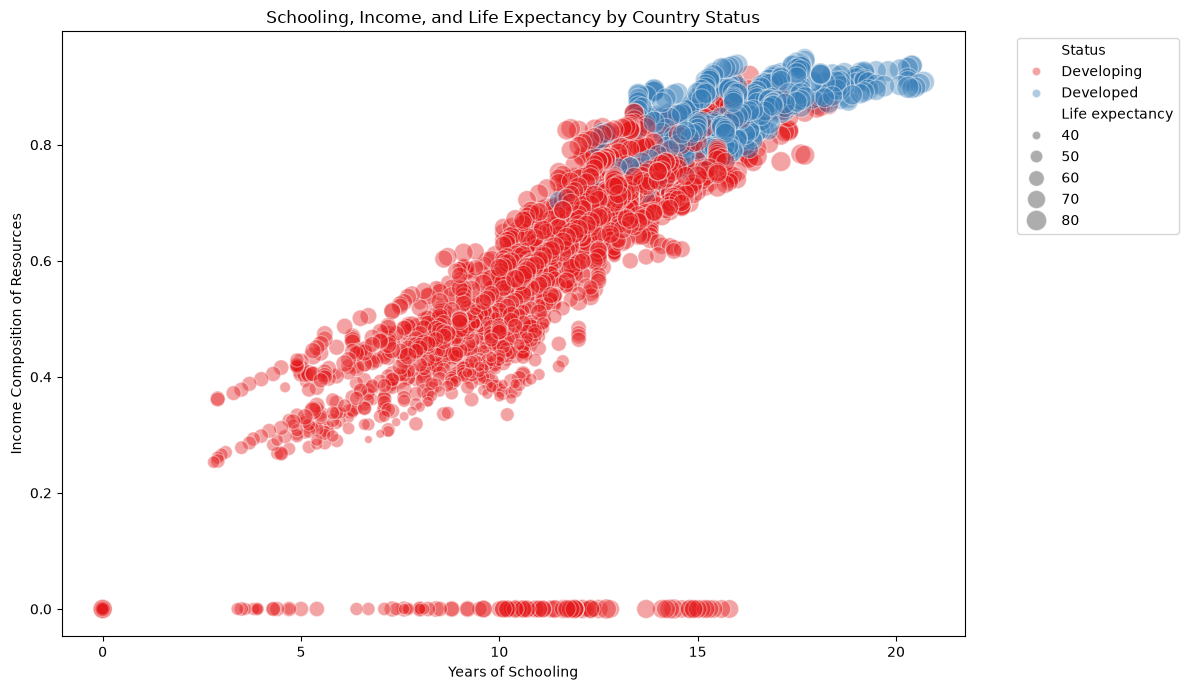

In [44]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Schooling',
    y='Income composition of resources',
    size='Life expectancy',
    hue='Status',
    sizes=(20, 250),
    alpha=0.4,
    palette='Set1'
)

plt.title('Schooling, Income, and Life Expectancy by Country Status')
plt.xlabel('Years of Schooling')
plt.ylabel('Income Composition of Resources')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

The bubble plot illustrates the relationship between education, income composition, and life expectancy. Each bubble represents an observation in the dataset, and its size represents life expectancy.

The visualization helps show how education and economic conditions are related to life expectancy across different countries.

In [45]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Load dataset
df = pd.read_csv('Life Expectancy Data.csv')

# Clean column names
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(r'\s+', ' ', regex=True)

# Select numerical features for PCA
features = [
    'Adult Mortality',
    'infant deaths',
    'Alcohol',
    'percentage expenditure',
    'Hepatitis B',
    'Measles',
    'BMI',
    'under-five deaths',
    'Polio',
    'Total expenditure',
    'Diphtheria',
    'HIV/AIDS',
    'GDP',
    'Population',
    'thinness 1-19 years',
    'thinness 5-9 years',
    'Income composition of resources',
    'Schooling'
]

# Select features from dataset
X = df[features].copy()

# Replace missing values with median
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Apply PCA with two principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Create DataFrame for PCA results
pca_df = pd.DataFrame(
    principal_components,
    columns=['PC1', 'PC2']
)

# Display explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nPC1 variance (%):")
print(pca.explained_variance_ratio_[0] * 100)

print("\nPC2 variance (%):")
print(pca.explained_variance_ratio_[1] * 100)

print("\nTotal explained variance (%):")
print(pca.explained_variance_ratio_.sum() * 100)

Explained variance ratio:
[0.30438067 0.14327238]

PC1 variance (%):
30.438067490598026

PC2 variance (%):
14.327237776405813

Total explained variance (%):
44.76530526700384


I performed Principal Component Analysis to reduce the original 18 numerical features into two principal components.

PCA helps simplify complex datasets by combining information from multiple variables into fewer dimensions.

The explained variance ratio shows how much information is preserved by each principal component. The combined explained variance indicates how much of the original dataset's variation is represented by the first two components.

Note: Use the percentages printed by your notebook in your final explanation.

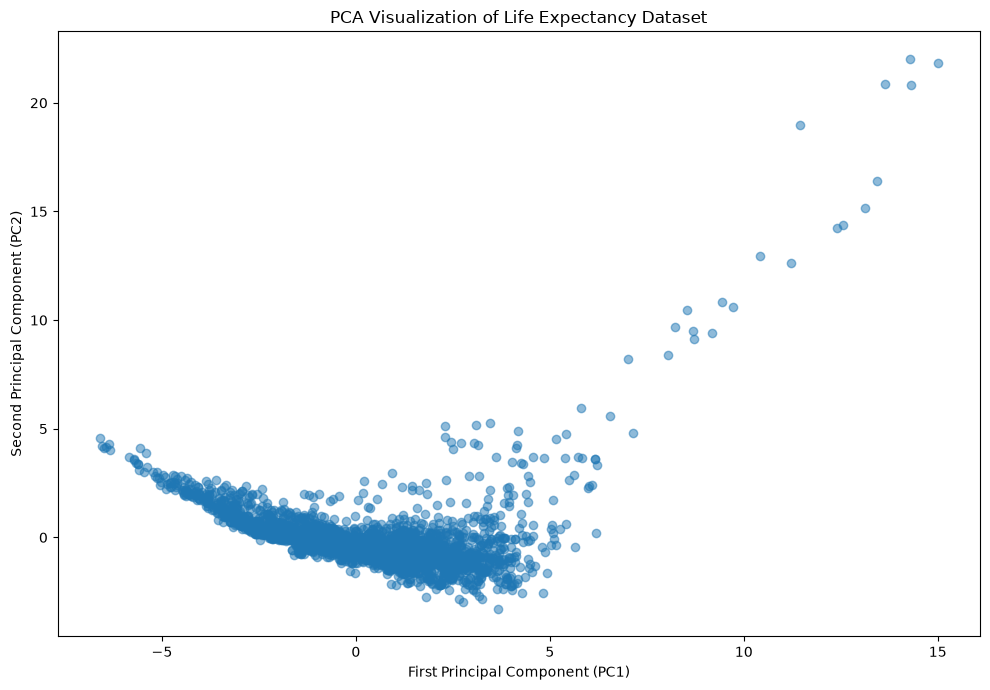

In [46]:
plt.figure(figsize=(10, 7))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha=0.5
)

plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')

plt.title('PCA Visualization of Life Expectancy Dataset')

plt.tight_layout()
plt.show()

The PCA scatter plot shows how the observations are distributed after reducing the dataset to two dimensions.

Most observations may form general clusters, while some points appear farther away from the main groups. These differences may reflect variations in health, education, and economic conditions across countries.

This visualization demonstrates how PCA can simplify a dataset with many variables.

In [47]:
# Select independent variables
features = [
    'Schooling',
    'Income composition of resources',
    'Adult Mortality',
    'BMI',
    'HIV/AIDS',
    'Diphtheria',
    'GDP',
    'thinness 1-19 years'
]

# Remove rows with missing target values
regression_df = df.dropna(subset=['Life expectancy']).copy()

# Independent variables
X = regression_df[features]

# Dependent variable
y = regression_df['Life expectancy']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create regression pipeline
model = make_pipeline(
    SimpleImputer(strategy='median'),
    LinearRegression()
)

# Train model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

# Evaluate model
r2 = r2_score(y_test, predictions)

rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("R-squared:", r2)
print("RMSE:", rmse)

R-squared: 0.8040476544066526
RMSE: 4.117008717206261


I used linear regression to predict life expectancy based on eight selected variables.

The dataset was divided into training and testing sets. The training data was used to build the model, while the testing data was used to evaluate its performance.

R-squared measures how well the model explains variations in life expectancy. RMSE measures the average prediction error, with smaller values indicating better predictions.

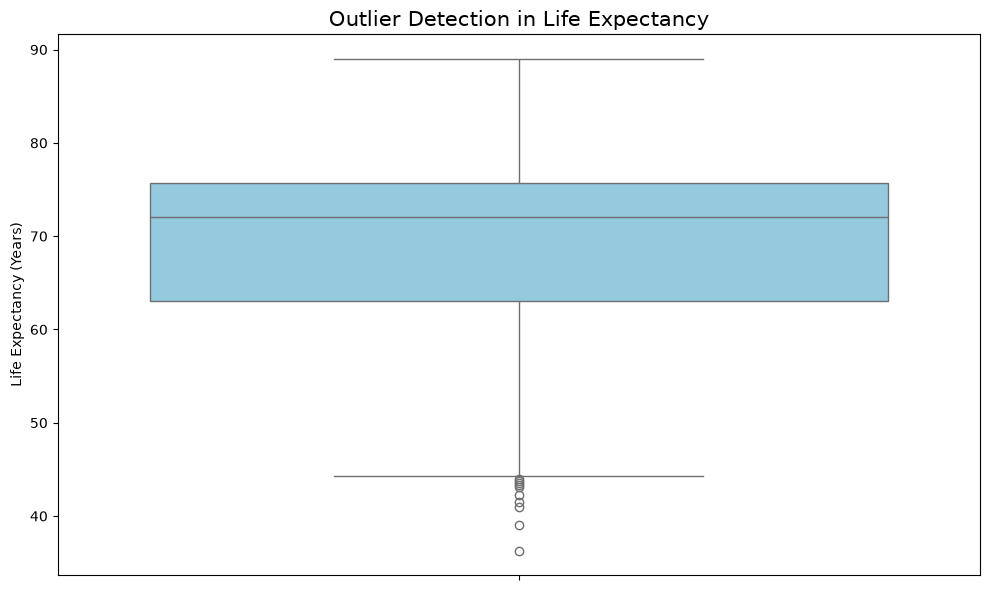

Number of potential outliers: 10
           Country  Year  Life expectancy
1127         Haiti  2010             36.3
1583        Malawi  2002             44.0
1584        Malawi  2001             43.5
1585        Malawi  2000             43.1
2307  Sierra Leone  2005             43.3
2308  Sierra Leone  2004             42.3
2309  Sierra Leone  2003             41.5
2311  Sierra Leone  2001             41.0
2312  Sierra Leone  2000             39.0
2921        Zambia  2000             43.8


In [48]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    y=df['Life expectancy'],
    color='skyblue'
)

plt.title('Outlier Detection in Life Expectancy',
          fontsize=15)

plt.ylabel('Life Expectancy (Years)')

plt.tight_layout()
plt.show()

# Calculate outliers using IQR
Q1 = df['Life expectancy'].quantile(0.25)
Q3 = df['Life expectancy'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Life expectancy'] < lower_bound) |
    (df['Life expectancy'] > upper_bound)
]

print("Number of potential outliers:", len(outliers))
print(outliers[['Country', 'Year', 'Life expectancy']].head(10))

I used a boxplot and the interquartile range (IQR) method to identify potential outliers in life expectancy.

The boxplot shows the distribution of life expectancy and highlights observations that fall outside the expected range.

Some countries may have unusually low or high life expectancy values because of differences in healthcare, economic conditions, and public health challenges.

Outliers should be investigated rather than automatically removed because they may represent important real-world conditions.

### Conclusion

Based on my analysis of the Life Expectancy dataset, I found that education, economic conditions, and health indicators are associated with life expectancy. The correlation heatmap showed positive relationships between life expectancy, schooling, and income composition of resources. In contrast, adult mortality and HIV/AIDS showed negative relationships with life expectancy. These patterns suggest that education and economic development are important factors to consider when studying life expectancy.

The bubble graph helped visualize the relationship between schooling, income composition, and life expectancy. However, the original graph was very dense because many observations overlapped. This made it difficult to distinguish individual data points. Using different colors for Developed and Developing countries can improve the visualization and make comparisons between the two groups easier.

The PCA analysis reduced the dataset to two principal components. PC1 explained approximately 30.44% of the variance, while PC2 explained approximately 14.33%. Together, they explained 44.77% of the total variance. Although PCA helped simplify the dataset, the two components did not capture most of the original information.

The linear regression analysis was used to examine whether selected health, education, and economic indicators could predict life expectancy. The boxplot and IQR method were also used to identify potential outliers. These observations may represent countries or years with unusual life expectancy values and should be investigated rather than automatically removed.

Overall, this project helped me understand how different health, education, and economic factors relate to life expectancy. It also showed me that visualizations and statistical methods have limitations. Using multiple approaches provides a more complete understanding of the data.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 136-150 of the Storytelling With Data book as best you can. ("The power of super-categories" to the end of chapter 5). You do not have to get the exact data values right, just the overall look and feel.

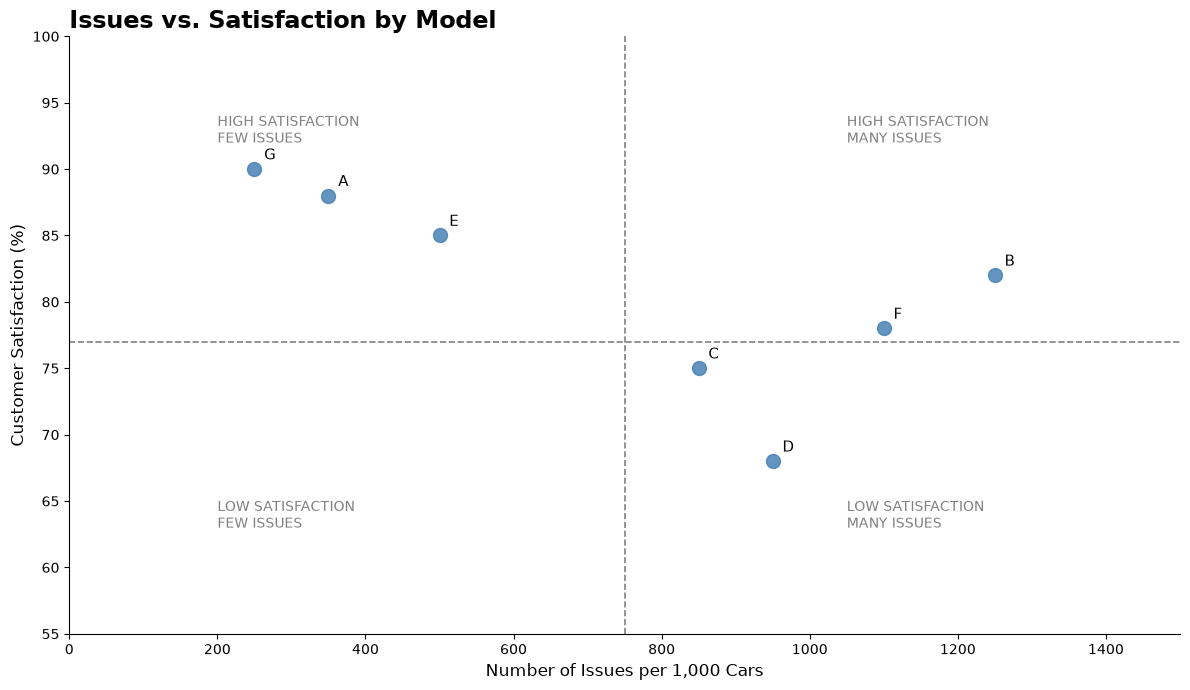

In [49]:
import matplotlib.pyplot as plt
import pandas as pd

# Illustrative data
data = {
    'Model': ['A', 'B', 'C', 'D', 'E', 'F', 'G'],
    'Issues': [350, 1250, 850, 950, 500, 1100, 250],
    'Satisfaction': [88, 82, 75, 68, 85, 78, 90]
}

df = pd.DataFrame(data)

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Plot the car models
ax.scatter(
    df['Issues'],
    df['Satisfaction'],
    s=100,
    color='steelblue',
    alpha=0.85
)

# Add model labels
for i, row in df.iterrows():
    ax.annotate(
        row['Model'],
        (row['Issues'], row['Satisfaction']),
        xytext=(7, 7),
        textcoords='offset points',
        fontsize=11
    )

# Add previous year average reference lines
ax.axvline(
    x=750,
    color='gray',
    linestyle='--',
    linewidth=1.2
)

ax.axhline(
    y=77,
    color='gray',
    linestyle='--',
    linewidth=1.2
)

# Add quadrant labels
ax.text(200, 92, 'HIGH SATISFACTION\nFEW ISSUES',
        fontsize=10, color='gray')

ax.text(1050, 92, 'HIGH SATISFACTION\nMANY ISSUES',
        fontsize=10, color='gray')

ax.text(200, 63, 'LOW SATISFACTION\nFEW ISSUES',
        fontsize=10, color='gray')

ax.text(1050, 63, 'LOW SATISFACTION\nMANY ISSUES',
        fontsize=10, color='gray')

# Titles and labels
ax.set_title(
    'Issues vs. Satisfaction by Model',
    fontsize=17,
    fontweight='bold',
    loc='left'
)

ax.set_xlabel('Number of Issues per 1,000 Cars', fontsize=12)
ax.set_ylabel('Customer Satisfaction (%)', fontsize=12)

ax.set_xlim(0, 1500)
ax.set_ylim(55, 100)

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(False)

plt.tight_layout()
plt.show()

I recreated Figure 5.6 from Chapter 5 of Storytelling With Data. The graph compares different car models based on customer satisfaction and the number of reported issues.

I used a scatter plot to show the relationship between these two measurements. I also added reference lines to divide the graph into four sections. These sections create super-categories that make it easier to compare the performance of different models.

I used simple colors, clear labels, and removed unnecessary visual elements to make the graph easier to understand. This example demonstrates how visual hierarchy and super-categories can help communicate information more effectively.